# Exploration du dataset Online Retail

Ce notebook sert à comprendre le fichier avant de choisir exactement ce que le modèle devra prédire. Il n’entraîne aucun modèle et ne modifie pas les données d’origine.

Une ligne correspond à une ligne de facture : un produit et une quantité, associés à une facture et une date. Une facture peut donc apparaître sur plusieurs lignes.

Le fichier provient du [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail). L’archive locale `online+retail.zip` doit être dans le même dossier que ce notebook.

## 1. Préparer les bibliothèques

Si la lecture Excel échoue avec un message indiquant que `openpyxl` manque, installe cette dépendance dans le projet TP01 avec `uv add openpyxl`, puis relance le kernel Jupyter.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', 80)

## 2. Lire le classeur directement depuis le ZIP

`pandas` sait lire le classeur Excel, mais pas directement le ZIP comme un fichier de données. Ici, on ouvre le ZIP en mémoire et on transmet le fichier `.xlsx` à `read_excel` : aucune extraction manuelle n’est nécessaire.

In [2]:
archive_path = Path('online+retail.zip')
if not archive_path.exists():
    raise FileNotFoundError(
        f'{archive_path} introuvable. Lance Jupyter depuis le dossier projet-ml-ops-prévision-vente.'
    )

with ZipFile(archive_path) as archive:
    excel_files = [name for name in archive.namelist() if name.lower().endswith('.xlsx')]
    if len(excel_files) != 1:
        raise ValueError(f'Un seul fichier .xlsx était attendu dans le ZIP, trouvé : {excel_files}')
    excel_bytes = archive.read(excel_files[0])

df = pd.read_excel(BytesIO(excel_bytes), engine='openpyxl')
print(f'Fichier lu : {excel_files[0]}')
print(f'Taille en mémoire : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')
display(df.head())

Fichier lu : Online Retail.xlsx
Taille en mémoire : 541,909 lignes × 8 colonnes


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Comprendre une ligne et les colonnes

Regarde quelques lignes et la description des colonnes. `InvoiceNo` identifie une facture, `StockCode` un produit, `Quantity` la quantité de cette ligne, et `UnitPrice` son prix unitaire en livres sterling. Les colonnes `CustomerID` et `Country` décrivent le client associé quand ces informations sont présentes.

In [3]:
print('Dimensions :', df.shape)
print('Colonnes :', df.columns.tolist())
display(df.sample(min(8, len(df)), random_state=42))

Dimensions : (541909, 8)
Colonnes : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom
465024,576200,82482,WOODEN PICTURE FRAME WHITE FINISH,2,2011-11-14 12:14:00,2.95,15572.0,United Kingdom
477777,577076,22614,PACK OF 12 SPACEBOY TISSUES,12,2011-11-17 15:08:00,0.39,14362.0,United Kingdom
367855,568909,22596,CHRISTMAS STAR WISH LIST CHALKBOARD,12,2011-09-29 13:38:00,1.25,16818.0,United Kingdom


In [4]:
schema = pd.DataFrame({
    'type_pandas': df.dtypes.astype(str),
    'valeurs_non_nulles': df.notna().sum(),
    'valeurs_manquantes': df.isna().sum(),
    'pourcentage_manquant': (df.isna().mean() * 100).round(2),
    'valeurs_distinctes': df.nunique(dropna=True),
})
display(schema)

,type_pandas,valeurs_non_nulles,valeurs_manquantes,pourcentage_manquant,valeurs_distinctes
InvoiceNo,object,541909,0,0.00,25900
StockCode,object,541909,0,0.00,4070
Description,object,540455,1454,0.27,4223
Quantity,int64,541909,0,0.00,722
InvoiceDate,datetime64[us],541909,0,0.00,23260
UnitPrice,float64,541909,0,0.00,1630
CustomerID,float64,406829,135080,24.93,4372
Country,str,541909,0,0.00,38


### Interprétation :

Même si Pandas affiche certaines colonnes en object, leurs types métier sont plutôt :

| Colonne | Type conseillé | Sens |
|---|---|---|
| `InvoiceNo` | texte (`string`) | Identifiant de facture ; le préfixe `C` sert à repérer certaines annulations. |
| `StockCode` | texte (`string`) | Identifiant du produit, même s’il ressemble parfois à un nombre. |
| `Description` | texte nullable | Nom ou description du produit. |
| `Quantity` | entier (`int`) | Quantité sur cette ligne ; elle peut être négative pour un retour ou une correction. |
| `InvoiceDate` | date-heure (`datetime`) | Date et heure de la facture. |
| `UnitPrice` | décimal (`float`) | Prix unitaire en livres sterling. |
| `CustomerID` | identifiant nullable, conservé comme texte | Identifiant client ; certaines valeurs sont absentes. |
| `Country` | texte (`string`) | Pays du client. |


In [5]:
missing = (
    df.isna().sum()
      .rename('nombre_manquant')
      .to_frame()
      .assign(pourcentage=lambda table: (table['nombre_manquant'] / len(df) * 100).round(2))
      .sort_values('nombre_manquant', ascending=False)
)
display(missing)

,nombre_manquant,pourcentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


Il y a des valeurs manquantes pour Customer ID et Description alors que pour les autres colonnes, il n'y a aucune valeur manquante.

## 4. Vérifier les dates et la période couverte

La prévision doit respecter l’ordre du temps. On convertit donc `InvoiceDate` en date, puis on inspecte les dates min/max et la fréquence des transactions. Les dates historiques ne seront pas séparées au hasard pour entraîner et tester le modèle.

In [6]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
print('Dates impossibles :', df['InvoiceDate'].isna().sum())
print('Première date :', df['InvoiceDate'].min())
print('Dernière date :', df['InvoiceDate'].max())
print('Nombre de jours distincts :', df['InvoiceDate'].dt.date.nunique())
display(df['InvoiceDate'].describe())

Dates impossibles : 0
Première date : 2010-12-01 08:26:00
Dernière date : 2011-12-09 12:50:00
Nombre de jours distincts : 305


count                        541909
mean     2011-07-04 13:34:57.156386
min             2010-12-01 08:26:00
25%             2011-03-28 11:34:00
50%             2011-07-19 17:17:00
75%             2011-10-19 11:27:00
max             2011-12-09 12:50:00
Name: InvoiceDate, dtype: object

## 5. Examiner quantités, prix et annulations

Une facture dont le numéro commence par `C` correspond à une annulation selon la documentation UCI. Des quantités négatives peuvent aussi représenter des retours ou corrections. Il faut comprendre leur fréquence et leur effet avant de définir les ventes à prévoir.

In [7]:
df['is_cancellation'] = df['InvoiceNo'].astype(str).str.upper().str.startswith('C')
summary = pd.Series({
    'lignes_facture_annulée': int(df['is_cancellation'].sum()),
    'factures annulées distinctes': int(df.loc[df['is_cancellation'], 'InvoiceNo'].nunique()),
    'quantités négatives': int((df['Quantity'] < 0).sum()),
    'quantités nulles': int((df['Quantity'] == 0).sum()),
    'prix négatifs': int((df['UnitPrice'] < 0).sum()),
    'prix nuls': int((df['UnitPrice'] == 0).sum()),
})
display(summary.to_frame('nombre'))
display(df.loc[df['is_cancellation'] | (df['Quantity'] < 0)].head(10))

,nombre
lignes_facture_annulée,9288
factures annulées distinctes,3836
quantités négatives,10624
quantités nulles,0
prix négatifs,2
prix nuls,2515


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,is_cancellation
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,True
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,True
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,True
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom,True
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,True
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom,True


,count,mean,std,min,1%,5%,50%,95%,99%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,-2.00,1.00,3.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,0.19,0.42,2.08,9.95,18.0,38970.0


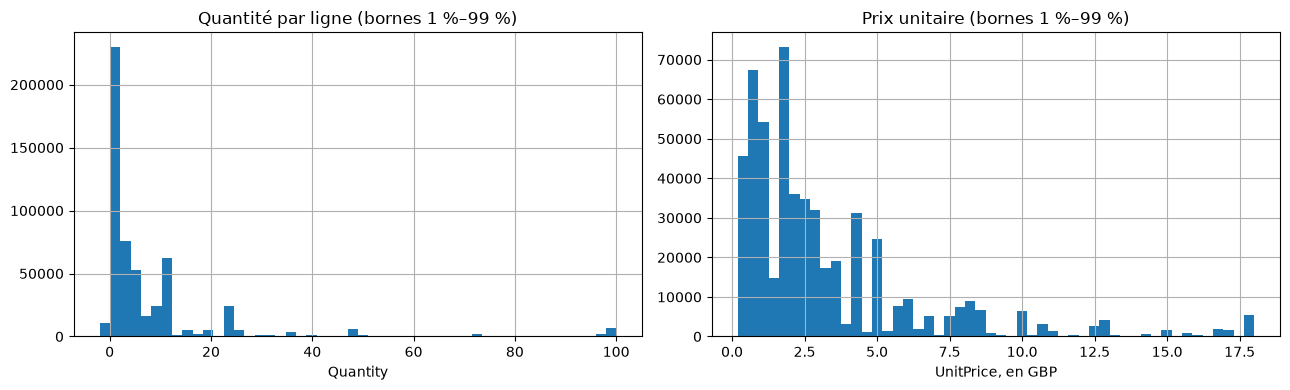

In [8]:
display(df[['Quantity', 'UnitPrice']].describe(percentiles=[.01, .05, .5, .95, .99]).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df['Quantity'].clip(lower=df['Quantity'].quantile(.01), upper=df['Quantity'].quantile(.99)).hist(bins=50, ax=axes[0])
axes[0].set_title('Quantité par ligne (bornes 1 %–99 %)')
axes[0].set_xlabel('Quantity')
df['UnitPrice'].clip(lower=df['UnitPrice'].quantile(.01), upper=df['UnitPrice'].quantile(.99)).hist(bins=50, ax=axes[1])
axes[1].set_title('Prix unitaire (bornes 1 %–99 %)')
axes[1].set_xlabel('UnitPrice, en GBP')
plt.tight_layout()
plt.show()

## 6. Mesurer les lignes répétées et la structure des factures

Plusieurs lignes peuvent appartenir à une même facture, et un même produit peut être vendu plusieurs fois. On vérifie les répétitions sans supprimer de ligne automatiquement. La clé exacte d’une ligne doit être décidée avec prudence : des lignes identiques peuvent être légitimes.

In [9]:
print('Lignes entièrement dupliquées :', int(df.drop(columns='is_cancellation').duplicated().sum()))
print('Factures distinctes :', df['InvoiceNo'].nunique())
print('Produits distincts :', df['StockCode'].nunique())
print('Clients distincts hors valeurs manquantes :', df['CustomerID'].nunique(dropna=True))
print('Pays distincts :', df['Country'].nunique())
display(df.groupby('InvoiceNo', dropna=False).size().describe().to_frame('lignes_par_facture'))

Lignes entièrement dupliquées : 5268
Factures distinctes : 25900
Produits distincts : 4070
Clients distincts hors valeurs manquantes : 4372
Pays distincts : 38


,lignes_par_facture
count,25900.000000
mean,20.923127
std,43.031334
min,1.000000
25%,2.000000
50%,10.000000
75%,23.000000
max,1114.000000


## 7. Construire plusieurs cibles possibles par jour

Le sujet parle de prévision des ventes, mais ne précise pas la mesure exacte. Voici trois cibles candidates :

1. **Quantité nette** : somme de `Quantity`, en gardant les retours et corrections négatifs.
2. **Quantité vendue brute** : somme des quantités positives des factures non annulées.
3. **Chiffre d’affaires net** : somme de `Quantity × UnitPrice`, en conservant les signes.

Ces définitions répondent à des questions différentes. La prochaine cellule les compare pour voir si elles sont régulières et interprétables. Les jours absents du fichier sont ajoutés avec zéro transaction ; vérifie ensuite si cette hypothèse convient au périmètre choisi.

In [10]:
daily_source = df.dropna(subset=['InvoiceDate']).copy()
daily_source['day'] = daily_source['InvoiceDate'].dt.normalize()
daily_source['line_revenue'] = daily_source['Quantity'] * daily_source['UnitPrice']
daily_source['gross_quantity'] = daily_source['Quantity'].where(
    (~daily_source['is_cancellation']) & (daily_source['Quantity'] > 0), 0
)

daily = daily_source.groupby('day').agg(
    net_quantity=('Quantity', 'sum'),
    gross_quantity=('gross_quantity', 'sum'),
    net_revenue_gbp=('line_revenue', 'sum'),
    invoice_count=('InvoiceNo', 'nunique'),
    transaction_lines=('InvoiceNo', 'size'),
)

calendar = pd.date_range(daily.index.min(), daily.index.max(), freq='D')
daily = daily.reindex(calendar, fill_value=0)
daily.index.name = 'day'
display(daily.head())
display(daily[['net_quantity', 'gross_quantity', 'net_revenue_gbp', 'invoice_count']].describe().T)

,net_quantity,gross_quantity,net_revenue_gbp,invoice_count,transaction_lines
day,,,,,
2010-12-01,26814,27007,58635.56,143,3108
2010-12-02,21023,31348,46207.28,167,2109
2010-12-03,14830,16471,45620.46,108,2202
2010-12-04,0,0,0.00,0,0
2010-12-05,16395,16451,31383.95,95,2725


,count,mean,std,min,25%,50%,75%,max
net_quantity,374.0,13840.775401,10456.831357,-13752.00,5651.0000,13591.00,19619.2500,46161.00
gross_quantity,374.0,15136.312834,12061.078158,0.00,7096.0000,14515.00,20880.2500,93979.00
net_revenue_gbp,374.0,26063.497150,20031.204764,-1566.23,10410.6575,25005.82,36982.6925,112141.11
invoice_count,374.0,69.251337,45.288719,0.00,38.2500,70.00,98.0000,218.00


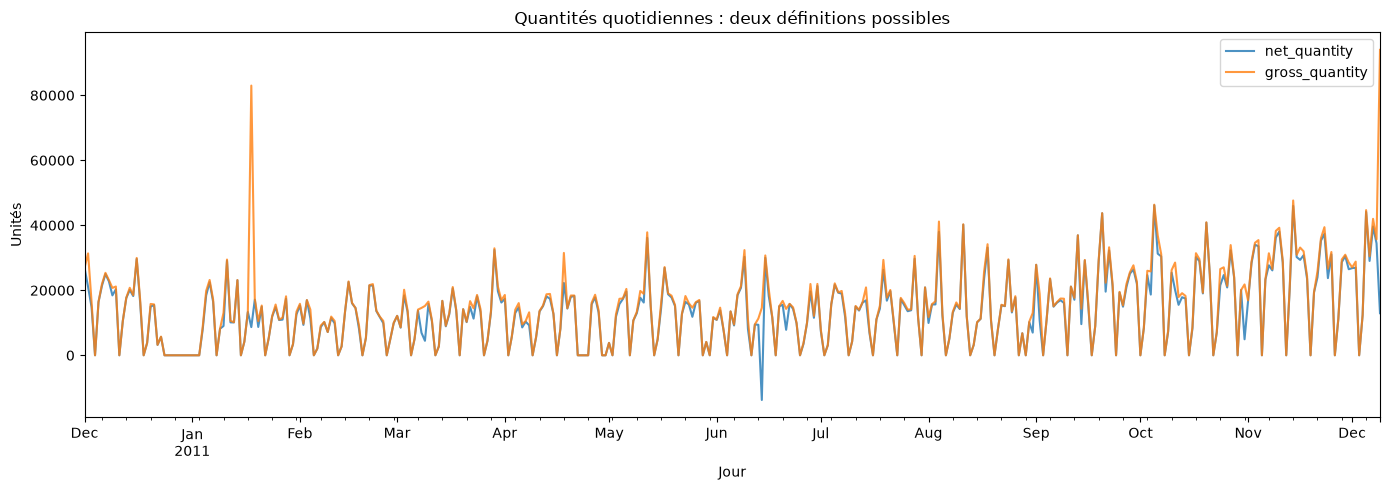

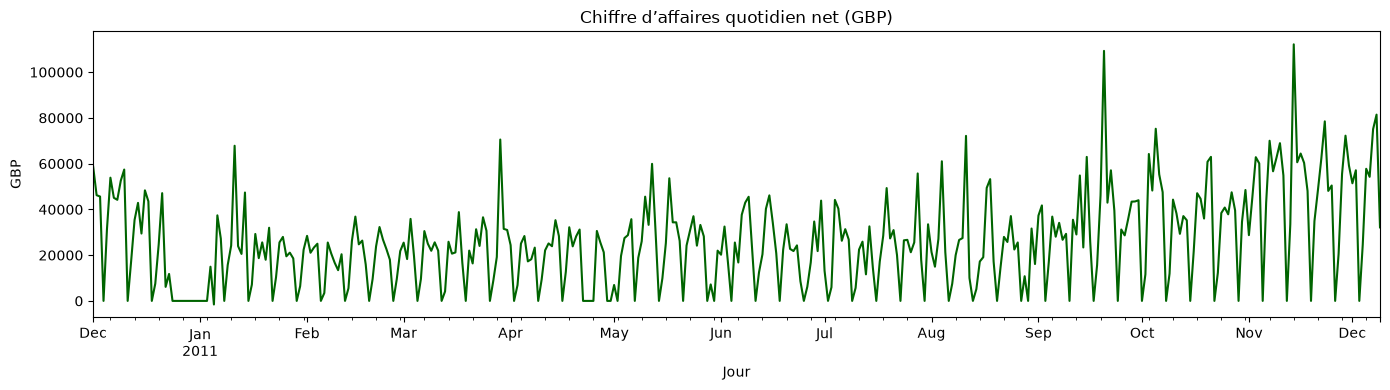

In [11]:
daily[['net_quantity', 'gross_quantity']].plot(figsize=(14, 5), alpha=0.8)
plt.title('Quantités quotidiennes : deux définitions possibles')
plt.ylabel('Unités')
plt.xlabel('Jour')
plt.tight_layout()
plt.show()

daily['net_revenue_gbp'].plot(figsize=(14, 4), color='darkgreen')
plt.title('Chiffre d’affaires quotidien net (GBP)')
plt.ylabel('GBP')
plt.xlabel('Jour')
plt.tight_layout()
plt.show()

## 8. Observer les rythmes hebdomadaires et mensuels

Une prévision peut être plus facile si les ventes suivent un rythme lié au jour de la semaine ou au mois. Ces graphiques aident à formuler des variables explicatives possibles ; ils ne démontrent pas encore qu’un modèle saura prédire correctement.

,quantité_brute_moyenne
weekday,
Monday,16618.094340
Tuesday,21176.169811
Wednesday,19193.222222
Thursday,22767.351852
Friday,17055.648148
Saturday,0.000000
Sunday,8886.962264


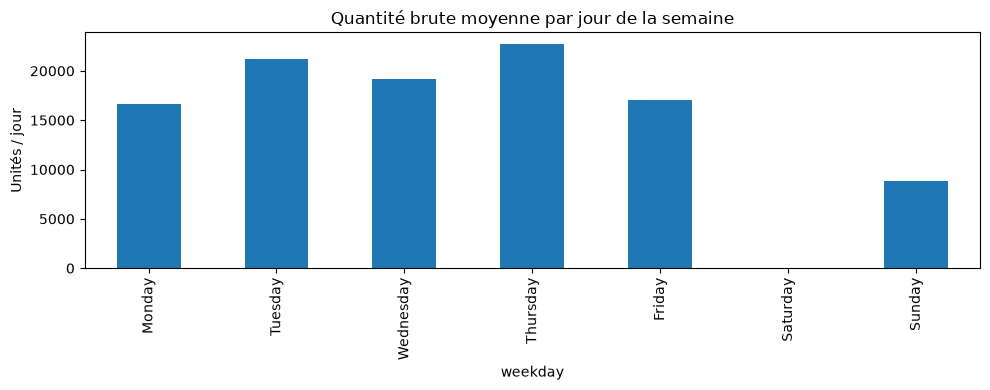

,quantité_brute_mensuelle
day,
2010-12-01,362316
2011-01-01,397716
2011-02-01,286695
2011-03-01,384950
2011-04-01,312176
2011-05-01,399425
2011-06-01,394337
2011-07-01,407539
2011-08-01,425016


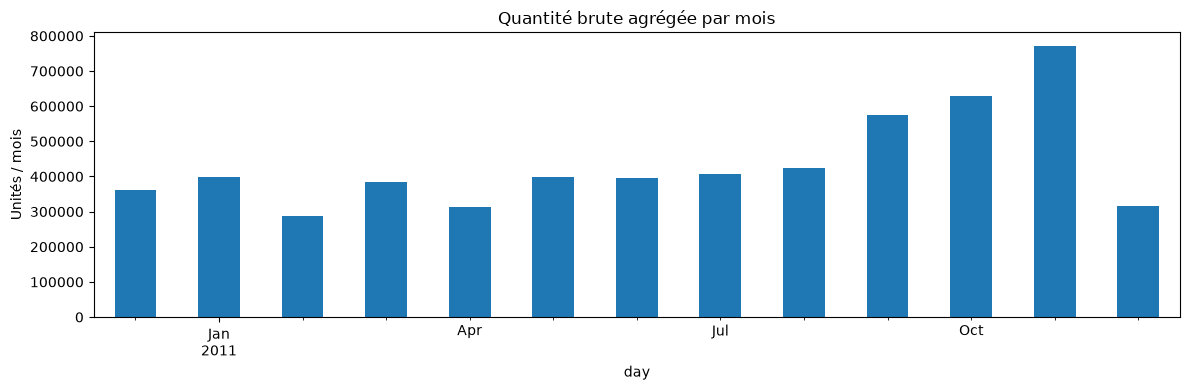

In [12]:
daily['weekday'] = daily.index.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_mean = daily.groupby('weekday')['gross_quantity'].mean().reindex(weekday_order)
display(weekday_mean.to_frame('quantité_brute_moyenne'))
weekday_mean.plot(kind='bar', figsize=(10, 4))
plt.title('Quantité brute moyenne par jour de la semaine')
plt.ylabel('Unités / jour')
plt.tight_layout()
plt.show()

monthly = daily['gross_quantity'].resample('MS').sum()
display(monthly.to_frame('quantité_brute_mensuelle'))
monthly.plot(kind='bar', figsize=(12, 4))
plt.title('Quantité brute agrégée par mois')
plt.ylabel('Unités / mois')
plt.tight_layout()
plt.show()

## 9. Questions à trancher avant de commencer le modèle

Réponds à ces questions dans tes notes :

- Que veux-tu prédire : unités vendues, chiffre d’affaires, nombre de factures, ou ventes d’un produit précis ?
- La cible doit-elle inclure les annulations et retours (mesure nette) ou mesurer les ventes positives seulement (mesure brute) ?
- Prévois-tu la valeur du lendemain à partir des jours précédents, ou une autre période ?
- Les jours sans transaction doivent-ils compter comme zéro pour ton cas d’usage ?
- Quelle baseline simple permettra de vérifier que le modèle apporte quelque chose, par exemple reprendre la valeur du même jour de la semaine précédente ?

Pour une prévision temporelle, le jeu de test doit contenir des dates postérieures au jeu d’entraînement. Ne mélange pas aléatoirement les journées, sinon des informations du futur pourraient influencer l’évaluation.

In [ ]:
# Résumé des valeurs candidates à comparer avant de choisir la cible.
candidate_summary = daily[['net_quantity', 'gross_quantity', 'net_revenue_gbp', 'invoice_count']].agg(
    ['min', 'median', 'mean', 'max', 'std']
).T
candidate_summary['jours_a_zero'] = (daily[['net_quantity', 'gross_quantity', 'net_revenue_gbp', 'invoice_count']] == 0).sum()
display(candidate_summary.round(2))

,min,median,mean,max,std,jours_a_zero
net_quantity,-13752.00,13591.00,13840.78,46161.00,10456.83,69
gross_quantity,0.00,14515.00,15136.31,93979.00,12061.08,69
net_revenue_gbp,-1566.23,25005.82,26063.50,112141.11,20031.20,69
invoice_count,0.00,70.00,69.25,218.00,45.29,69


## Mes choix pour les prédictions, les types de colonnes 

Que prédire ? : 
- prédire combien d’unités d’un produit précis seront vendues demain, en utilisant uniquement les jours précédents. C’est une prévision de série temporelle, au niveau produit × jour.

Quantité brute ou nette ? :
- (quantité brute) Pour chaque produit et chaque jour, on additionnera les Quantity positives, en excluant les lignes dont la facture est une annulation. Le résultat sera un entier positif ou nul. Cela est logique car on souhaite maximiser les ventes même si il y a une annulation plus tard.

Que faire des jours sans transactions ? :
- Quand un produit n’a aucune vente enregistrée un jour donné, sa quantité brute ce jour-là vaut 0.
C’est important : sans cette ligne à zéro, le modèle pourrait interpréter deux ventes espacées de trois jours comme deux jours consécutifs. Attention toutefois, zéro signifie ici « aucune vente observée », pas forcément « demande nulle » : le produit pouvait être indisponible. Le dataset ne permet pas toujours de distinguer ces situations.

Quels produits précis choisir pour la prédiction ? :
- Une première règle simple serait de garder les produits ayant assez d’historique, et de documenter le seuil. On pourra prendre les 10 premiers produits les plus vendues.

Quelle serait la baseline ? :
- pour prévoir un mardi, prendre les quantités des quatre mardis précédents et en faire la moyenne. Elle utilise bien le passé uniquement.


Quelles seraient les types de colonnes, contrat de données : 

| Colonne | Type conseillé | Sens |
|---|---|---|
| `InvoiceNo` | texte (`string`) | Identifiant de facture ; le préfixe `C` sert à repérer certaines annulations. |
| `StockCode` | texte (`string`) | Identifiant du produit, même s’il ressemble parfois à un nombre. |
| `Description` | texte nullable | Nom ou description du produit. |
| `Quantity` | entier (`int`) | Quantité sur cette ligne ; elle peut être négative pour un retour ou une correction. |
| `InvoiceDate` | date-heure (`datetime`) | Date et heure de la facture. |
| `UnitPrice` | décimal (`float`) | Prix unitaire en livres sterling. |
| `CustomerID` | identifiant nullable, conservé comme texte | Identifiant client ; certaines valeurs sont absentes. |
| `Country` | texte (`string`) | Pays du client. |